In [27]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

r_min = 0.1
x_min = np.sqrt(r_min)
nu = 1
timesteps = 5000000

x, dx  = np.linspace(0.1, 3, 1000, retstep=True)

f = np.exp(-(x**2 - 3)**2/(2*r_min))

def apply_boundary_conditions(f):
    #f[0] = 0.0
    f[0] = (4 * f[1] - f[2]) / 3
    #f[-1] = (4 * f[-2] - f[-3]) / 3
    # Outer boundary: dSigma/dr = 0
    sigma_outer = (4 * f[-2] / x[-2] - f[-3] / x[-3]) / 3
    f[-1] = x[-1] * sigma_outer
#centered_finite_differences stencil:
res = np.zeros(shape=(timesteps, 1000))
for i in range(timesteps):
    D = 3*nu/(4*x[1:-1]**2)
    left, center, right = f[:-2], f[1:-1], f[2:]
    f_xx = (left - 2 * center + right) / dx**2

    dt = 0.4 * dx**2 / np.max(D)  # below the CFL limit of 0.5
    f_new = f.copy()
    f_new[1:-1] = center + dt * D * f_xx
    apply_boundary_conditions(f_new)

    if i%1000==0:
        res[i] = f_new
    f = f_new.copy()




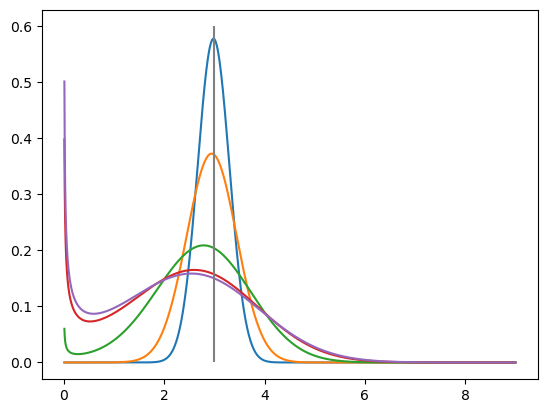

In [28]:
x_plot = x
plt.plot(x**2, res[0]/x)
plt.plot(x**2, res[500000]/x)
plt.plot(x**2, res[2500000]/x)
plt.plot(x**2, res[-500000]/x)
plt.plot(x**2, res[-1000]/x)
plt.vlines(x=3, ymin=0, ymax=0.6, colors="grey")